# Caso 2 · Red + generación térmica + PV fijo + BESS, primera comparación controlada

**Alcance al cierre del 16/09/2026.** Este cuaderno es una comparación controlada
y sus §§7–8 son sensibilidades complementarias de límites y cargos de arranque.
Mantiene SOC inicial/final fijo del 60 % y ausencia de exportación. La comparación
principal de reglas integradas está en el **cuaderno 14**, con SOC cíclico libre
y otras posibilidades de exportación. Estas curvas no calibran el costo real
de arranque ni prueban la robustez del ranking A/B/D/C/F.

Auditoría de cierre: `resultados_nb13/cierre_20260916/` y `CIERRE_TESIS.md`.

¿Permite almacenar los excedentes solares reducir **a la vez** el vertimiento y
los arranques térmicos? Se agrega un BESS al caso 1 (cuaderno 12) y se mantiene
todo lo demás exactamente igual.

```
RED + G1–G4 ─────────────────────────────► DEMANDA
PV ──directo──────────────────────────────►
 └──carga──► [BESS] ──descarga───────────►     (vertimiento permitido; sin exportación)
```

| capa | archivo | papel |
|---|---|---|
| Modelo | `termica_pypsa.py` | `bess` agrega el almacenamiento; sin él, el modelo es el del caso 1 |
| Caso 2 | `termica_bess.py` | parámetros, validador independiente, indicadores, unidades y economía |
| Pruebas | `termica_bess_pruebas.py` | casos analíticos, BESS cero, MILP independiente con BESS |
| Cálculo | `termica_bess_anual.py` | año completo T0 y T1; reutiliza el caso 1 como referencia |
| Límites anuales | `termica_bess_limites.py` | curva de costo con tamaños fijos y cotas, presentada en §7 |
| Pruebas de límites | `termica_bess_limites_pruebas.py` | MILP independiente, frontera anual y conservación de candidatos |
| Cargo sin límite anual | `termica_bess_cargos.py` y `termica_costo_arranque.py` | componentes y respuesta económica, §8 |
| Lectura | este cuaderno | solo lee `resultados_nb13/` |

Este cuaderno **no resuelve ningún modelo**: una guarda interrumpe la ejecución
si alguna celda intentara llamar a los solvers.

In [1]:
import sys, warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown

warnings.filterwarnings("ignore")
import termica as _T

SAL = Path("resultados_nb13")
NB12 = Path("resultados_nb12")
FIG = Path("figuras_nb13"); FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)


# --- Guarda: este cuaderno solo lee resultados. Si algo intenta recalcular, para. ---
def _prohibido(nombre):
    def _f(*a, **k):
        raise RuntimeError("El cuaderno 13 no debe recalcular nada: se intentó llamar a {}. "
                           "Las fuentes son resultados_nb13/, que escribe termica_bess_anual.py.".format(nombre))
    return _f


for _nombre in ("cargar_entradas", "enumerar_termico", "resolver_compromiso_temporal",
                "resolver_eventos", "contraste_milp_compromiso"):
    setattr(_T, _nombre, _prohibido(_nombre))
sys.modules["termica_pypsa"] = None      # importar el modelo PyPSA falla a propósito


def es(x, dec=0):
    """Número con coma decimal y punto de miles, como pide la prosa del proyecto."""
    return f"{x:,.{dec}f}".replace(",", "§").replace(".", ",").replace("§", ".")


# Paleta validada con .build/validar_paleta.py sobre #fcfcfb: visión normal y tritan PASS;
# deutan/protan WARN en G3<->Red; PV (2,1:1) y BESS (2,6:1) exigen etiqueta directa y borde.
COLOR = {"G1+G2": "#2a78d6", "G3": "#a03060", "G4": "#0d5f4f", "Red": "#8b8a83", "PV": "#eda100",
         "BESS": "#e87ba4"}
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#d8d8d4", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#d8d8d4", "font.size": 9.5})

RES = pd.read_csv(SAL/"bess_anual_resumen.csv", float_precision="round_trip")
DIF = pd.read_csv(SAL/"bess_anual_diferencias.csv", float_precision="round_trip")
UNI = pd.read_csv(SAL/"bess_unidades.csv", float_precision="round_trip")
EOHD = pd.read_csv(SAL/"bess_eoh_diferencias.csv", float_precision="round_trip")
COMP = pd.read_csv(SAL/"bess_compromiso_diferencias.csv")
HORA = pd.read_csv(SAL/"bess_arranques_por_hora.csv")
ECO = pd.read_csv(SAL/"bess_economia_referencia.csv", float_precision="round_trip")
VER = pd.read_csv(SAL/"bess_verificaciones.csv", float_precision="round_trip")
PRU = pd.read_csv(SAL/"bess_pruebas.csv", float_precision="round_trip")
assert (PRU.Estado == "OK").all() and (VER.Estado == "OK").all()
assert len(RES) == 4 and set(RES.Caso) == {"sin_BESS", "con_BESS"}
fila = lambda s, caso: RES[(RES.Senal == s) & (RES.Caso == caso)].iloc[0]
print("{} pruebas cortas y {} verificaciones anuales en OK.".format(len(PRU), len(VER)))
print("Estado con BESS:", dict(zip(RES[RES.Caso == "con_BESS"].Senal, RES[RES.Caso == "con_BESS"].Estado_solucion)))

15 pruebas cortas y 4 verificaciones anuales en OK.
Estado con BESS: {'T0': 'FACTIBLE_LIMITE_TIEMPO', 'T1': 'FACTIBLE_LIMITE_TIEMPO'}


## 1 · Supuestos

**Iguales al caso 1** (cuaderno 12):
- demanda y señales T0/T1;
- PV de 114,415019 MWp DC en Oriente, con vertimiento permitido y sin exportación;
- G1–G4 con HR de fabricante, mínimos del 30 % y gas a 16 USD/MMBtu;
- como máximo un arranque y una parada por unidad y día; estado inicial libre;
- 0 minutos por evento y cargo **hipotético** de 100 USD/arranque.

No se agregan límites anuales de arranques: se busca el efecto propio del
almacenamiento.

**BESS de prueba: K3 = 45 MW / 280 MWh (6,22 h).** Es la configuración
representativa vigente (INFORME §0.3–0.4). Encaja con el orden de magnitud del
problema:
- el vertimiento diario mediano del caso 1 es de unos 265 MWh;
- la capacidad útil es 224 MWh;
- la demanda en horas sin sol ronda 225 MWh/día.

Se obtuvo para PV+BESS **con exportación y sin térmica**, así que aquí es un
**punto de prueba, no un tamaño óptimo** ni un dimensionamiento final.

| parámetro | valor | origen |
|---|---|---|
| Potencia de carga y de descarga (AC) | 45 MW | K3 |
| Energía nominal | 280 MWh | K3 |
| DoD / SOC permitido | 0,8 / 20–100 % | cuaderno 02 (`DoD`) |
| Eficiencia de ida y vuelta | 90 %, con η_c = η_d = √0,9 | cuaderno 02 (`ETA_RT`, `ETA_C`, `ETA_D`) |
| SOC inicial = SOC final | 60 % (168 MWh), punto medio del rango | **supuesto de este caso** |
| Carga | **solo desde PV** | supuesto de esta primera comparación |
| Degradación y mantenimiento en el despacho | no se incluyen | el `c_deg` del cuaderno 02 es un precio sombra de otra formulación |
| CAPEX / OPEX | `costos.capex_bess` (curvas) y 1,5 % del CAPEX al año | se reportan aparte del costo operativo |

**Formulación.**
- **Carga solo desde PV.** El PV tiene un bus propio, del que salen dos enlaces
  unidireccionales: PV→demanda y PV→BESS. Ningún enlace entra a ese bus, así que
  la red y la térmica no pueden cargar el BESS por construcción.
- **Sin simultaneidad.** Hay dos formulaciones exactas y equivalentes, ambas
  probadas:
  - **Binaria** (`bess_exclusion='binaria'`): `carga ≤ P·x`, `descarga ≤ P·(1−x)`,
    solo en las horas con PV. En las demás la carga ya es cero.
  - **Relajación con reparación exacta**, la usada en el año completo. Se resuelve
    sin binarias de modo, que es una relajación del modelo binario y por tanto
    una cota inferior de su costo. En cada hora con carga c y descarga d
    simultáneas, `reparar_simultaneidad` las sustituye por el flujo neto. El SOC y
    el suministro a la demanda se conservan; lo que la descarga dejaba de entregar
    lo cubre PV directo que se vertía. Térmica, red y costo no cambian. La
    solución reparada es factible para el modelo binario con el costo de su cota,
    así que es óptima con la misma brecha.

  No se confía en que las pérdidas eviten la simultaneidad: en la relajación sí
  aparece, con costo nulo, cuando hay vertimiento. Se usa esta vía porque con
  binarias el año T0 no bajó del 1,72 % de brecha en 1.800 s, y con la relajación
  llegó al 0,155 % en 600 s. En las ventanas cortas ambas vías dan el mismo costo
  que el MILP independiente.
- **SOC.** Sigue `SOC[t] = SOC[t−1] + η_c·carga − descarga/η_d`, entre 56 y
  280 MWh, con SOC final igual al inicial.
- **Qué es el despacho.** Es una **referencia con información completa del
  año**: no hay pronósticos ni horizonte rodante.

## 2 · Validación en ventanas cortas

`termica_bess_pruebas.py` ejecuta las siguientes pruebas.

**Casos analíticos**
- **Desplazamiento con pérdidas.** Costo 2.070 USD frente a 4.500 sin BESS: carga
  10 MWh, descarga 8,1 y vierte 5.
- **Sin carga desde red.** Con PV nulo y un arbitraje de red muy rentable, el BESS
  no carga y el costo es exactamente 5.050 USD.

**Regresión.** El camino sin BESS reproduce los costos guardados de
`resultados_nb12/pv_pruebas.csv`.

**Tres ventanas reales, en T0 y T1**
- **BESS de capacidad cero:** reproduce el costo sin BESS.
- **BESS K3:** pasa la validación independiente —balance, límites y dinámica del
  SOC, cierre, pérdidas, carga solo desde PV, sin simultaneidad, sin
  exportación, transiciones, eventos diarios y costo—.
- **Contraste MILP:** coincide con un MILP de SciPy formulado aparte, con binaria
  de modo en **todas** las horas.
- **Cota:** el costo con BESS no supera el costo sin BESS.

In [2]:
display(PRU)
print("error máximo frente al MILP con BESS: {:.1e} USD; BESS cero frente a sin BESS: {:.1e} USD".format(
    PRU.Error_MILP_USD.max(), PRU.Error_vs_sin_BESS_USD.max()))

,Prueba,Senal,Horas,Costo_PyPSA_USD,PV_vertido_MWh,BESS_carga_MWh,BESS_descarga_MWh,Binarias_BESS,Arranques,Paradas,Brecha,Segundos,Estado,Error_MILP_USD,Error_vs_sin_BESS_USD,Costo_sin_BESS_USD,Error_regresion_nb12_USD,Residuo_SOC_MWh,Horas_simultaneas,Error_relajada_vs_binaria_USD,Horas_simultaneas_relajada
0,sintetica_desplazamiento_con_perdidas,-,4,2070.000000,5.000000,10.000000,8.100000,1.0,0.0,0.0,0.000000e+00,1.304005,OK,0.000000e+00,NaN,4500.000000,NaN,NaN,NaN,NaN,NaN
1,sintetica_sin_carga_desde_red,-,2,5050.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000e+00,1.436805,OK,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,sintetica_reparacion_simultaneidad,-,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,OK,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,demanda_baja_con_sol_BESS_cero,T0,48,26605.941632,981.335232,0.000000,0.000000,0.0,0.0,3.0,1.093885e-15,0.957949,OK,NaN,0.0,26605.941632,0.0,NaN,NaN,NaN,NaN
4,demanda_baja_con_sol_BESS_K3,T0,48,5391.025953,846.276866,135.058366,121.552529,24.0,0.0,2.0,0.000000e+00,1.014383,OK,0.000000e+00,NaN,26605.941632,NaN,2.842171e-14,0.0,9.094947e-13,4.0
5,demanda_baja_con_sol_BESS_cero,T1,48,25636.181883,981.335232,0.000000,0.000000,0.0,0.0,2.0,0.000000e+00,1.484754,OK,NaN,0.0,25636.181883,0.0,NaN,NaN,NaN,NaN
6,demanda_baja_con_sol_BESS_K3,T1,48,5391.025953,846.276866,135.058366,121.552529,24.0,0.0,2.0,0.000000e+00,1.582199,OK,1.818989e-12,NaN,25636.181883,NaN,2.842171e-14,0.0,1.818989e-12,5.0
7,horas_solares_BESS_cero,T0,48,74502.889019,719.132840,0.000000,0.000000,0.0,5.0,4.0,0.000000e+00,1.389521,OK,NaN,0.0,74502.889019,0.0,NaN,NaN,NaN,NaN
8,horas_solares_BESS_K3,T0,48,4107.369758,246.899376,472.233464,425.010118,24.0,2.0,3.0,0.000000e+00,1.810395,OK,9.094947e-13,NaN,74502.889019,NaN,2.842171e-14,0.0,9.094947e-13,5.0
9,horas_solares_BESS_cero,T1,48,74545.329474,719.132840,0.000000,0.000000,0.0,6.0,5.0,0.000000e+00,1.508456,OK,NaN,0.0,74545.329474,0.0,NaN,NaN,NaN,NaN


error máximo frente al MILP con BESS: 1.1e-11 USD; BESS cero frente a sin BESS: 0.0e+00 USD


## 3 · Resultados anuales

**Sin BESS** se reutiliza la trayectoria anual del caso 1, revalidada. **Con
BESS** se resuelve el año en PyPSA con brecha relativa solicitada de 1e−6 y un
límite de 3.600 s por señal. Si el solver termina por tiempo, la tabla lo marca
`FACTIBLE_LIMITE_TIEMPO`: la solución guardada es factible y está validada, pero
no es un óptimo certificado. El óptimo queda entre la cota dual y el costo
factible. Esa brecha acota el **costo**, no los arranques, las horas ni el
vertimiento.

**Definiciones.** La energía cargada y luego descargada no se cuenta dos veces.
- **PV entregado a la demanda:** PV directo + descarga del BESS.
- **PV generado:** PV directo + carga del BESS.
- **Pérdidas del BESS:** carga − descarga − ΔSOC, con ΔSOC = 0.
- **Ciclos equivalentes:** energía descargada entregada (lado AC) / capacidad útil
  (280 × 0,8 = 224 MWh), la convención de `factorial_operativo`. También se
  reportan sobre la energía nominal.

In [3]:
columnas = ["Senal", "Caso", "Estado_solucion", "Condicion_solver", "Brecha", "Brecha_solicitada", "Cota_dual_USD",
            "Segundos", "Exclusion_simultanea", "Horas_reparadas", "Intentos","PV_disponible_MWh", "PV_directo_demanda_MWh", "PV_a_BESS_MWh",
            "PV_vertido_MWh", "Vertimiento_pct", "BESS_descarga_demanda_MWh", "BESS_perdidas_MWh",
            "PV_entregado_demanda_MWh", "Participacion_PV_demanda_pct", "BESS_ciclos_equivalentes_util",
            "BESS_ciclos_equivalentes_nominal", "Energia_termica_MWh", "Compras_red_MWh", "Gas_MMBtu",
            "Costo_combustible_USD", "Costo_CVOM_USD", "Costo_red_USD", "Costo_arranques_USD",
            "Costo_operativo_total_USD", "Arranques", "Arranques_G1_G2", "Arranques_G3", "Arranques_G4", "Paradas"]
display(RES[columnas].round(3).T)
display(DIF.round(2).T)
display(VER.T)

,0,1,2,3
Senal,T0,T0,T1,T1
Caso,sin_BESS,con_BESS,sin_BESS,con_BESS
Estado_solucion,PRECISION_SOLICITADA,FACTIBLE_LIMITE_TIEMPO,PRECISION_SOLICITADA,FACTIBLE_LIMITE_TIEMPO
Condicion_solver,ok/optimal,ok/time_limit,ok/optimal,ok/time_limit
Brecha,0.0,0.002,0.0,0.001
Brecha_solicitada,0.0,0.0,0.0,0.0
Cota_dual_USD,16167922.67,5031990.451,16047586.092,5031753.939
Segundos,109.623,604.722,110.687,604.371
Exclusion_simultanea,-,relajada + reparación exacta,-,relajada + reparación exacta
Horas_reparadas,NaN,604.0,NaN,605.0


,0,1
Senal,T0,T1
Delta_Costo_operativo_total_USD,-11127994.01,-11008955.73
Delta_Costo_combustible_USD,-10226764.01,-9323747.12
Delta_Costo_CVOM_USD,-596515.36,-550254.35
Delta_Costo_red_USD,-239114.64,-1069554.27
Delta_Costo_arranques_USD,-65600.0,-65400.0
Delta_PV_generado_MWh,72852.86,72856.13
Delta_PV_directo_demanda_MWh,-1507.78,-1461.85
Delta_PV_vertido_MWh,-72852.86,-72856.13
Delta_PV_entregado_demanda_MWh,65416.8,65424.33


,0,1,2,3
Senal,T0,T0,T1,T1
Caso,sin_BESS,con_BESS,sin_BESS,con_BESS
Residuo_balance_MW,0.0,0.0,0.0,0.0
Residuo_PV_MW,0.0,0.0,0.0,0.0
Eventos_dia_max,1,1,1,1
Error_reconstruccion_costo_USD,0.0,0.0,0.0,0.0
Estado,OK,OK,OK,OK
Residuo_SOC_MWh,NaN,0.0,NaN,0.0
Cierre_SOC_MWh,NaN,0.0,NaN,0.0
Horas_simultaneas,NaN,0.0,NaN,0.0


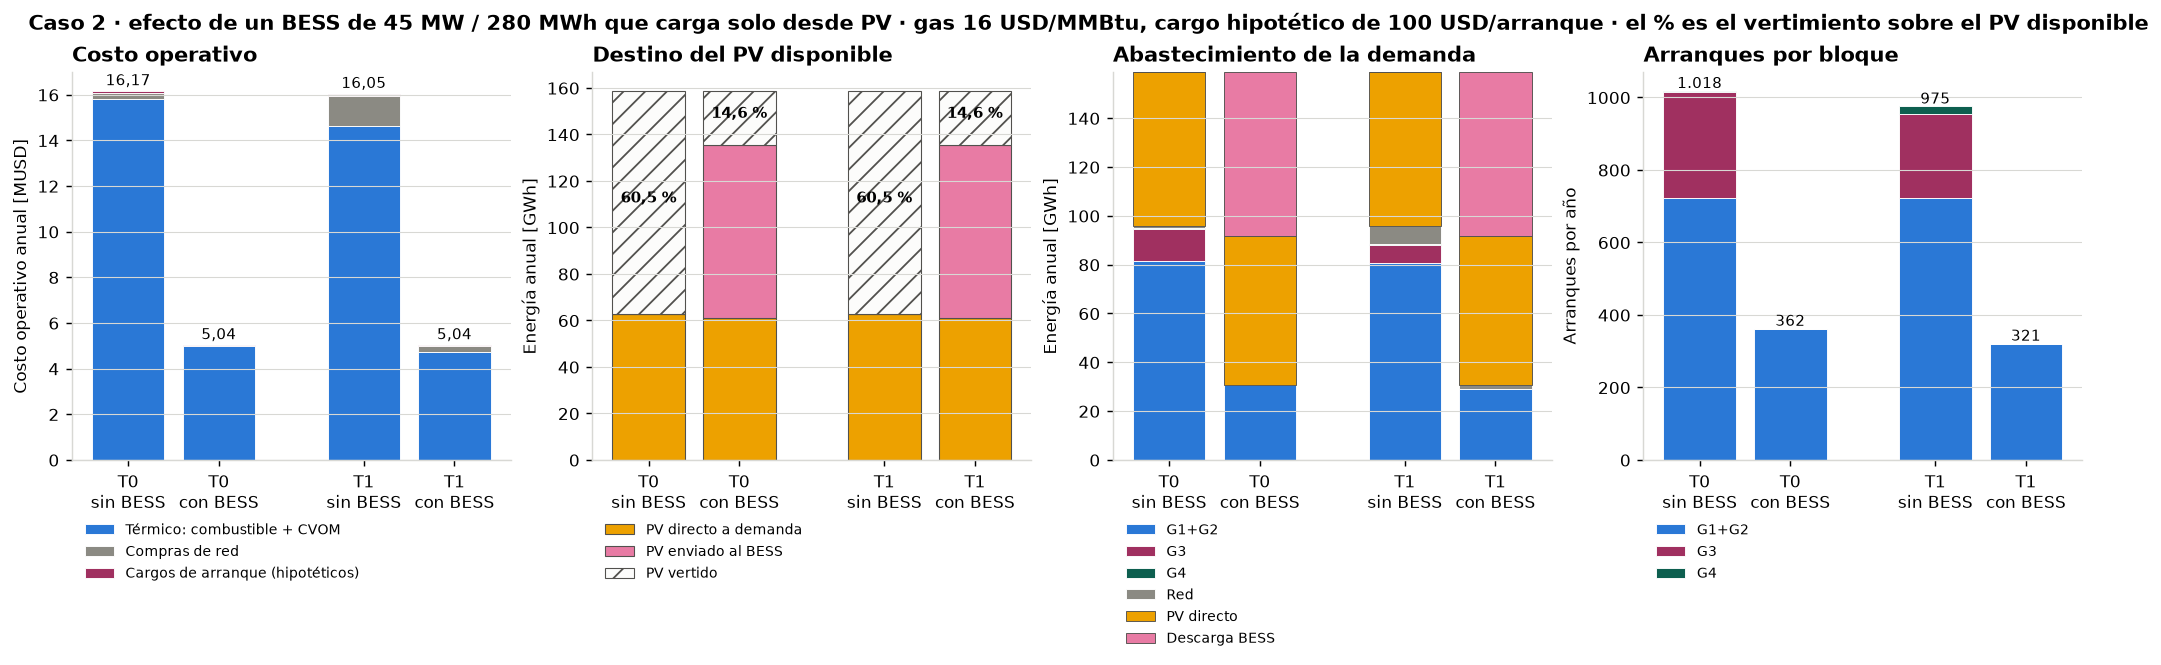

In [4]:
# A. Comparación anual sin y con BESS: costos, destino del PV y abastecimiento, arranques.
orden = [("T0", "sin_BESS"), ("T0", "con_BESS"), ("T1", "sin_BESS"), ("T1", "con_BESS")]
etiquetas = ["T0\nsin BESS", "T0\ncon BESS", "T1\nsin BESS", "T1\ncon BESS"]
x = np.array([0, 1, 2.6, 3.6])
F = [fila(s, c) for s, c in orden]
fig, axs = plt.subplots(1, 4, figsize=(16, 5), layout="constrained")

ax = axs[0]
base = np.zeros(4)
for nombre, valor, color in [("Térmico: combustible + CVOM", lambda f: f.Costo_combustible_USD + f.Costo_CVOM_USD, COLOR["G1+G2"]),
                             ("Compras de red", lambda f: f.Costo_red_USD, COLOR["Red"]),
                             ("Cargos de arranque (hipotéticos)", lambda f: f.Costo_arranques_USD, COLOR["G3"])]:
    v = np.array([valor(f) for f in F])/1e6
    ax.bar(x, v, 0.8, bottom=base, color=color, label=nombre, edgecolor="white", linewidth=0.5)
    base += v
for xi, total in zip(x, base):
    ax.text(xi, total+0.25, es(total, 2), ha="center", fontsize=8.5)
ax.set_ylabel("Costo operativo anual [MUSD]")
ax.set_title("Costo operativo", loc="left", fontweight="bold")

ax = axs[1]
base = np.zeros(4)
for nombre, col, color in [("PV directo a demanda", "PV_directo_demanda_MWh", COLOR["PV"]),
                           ("PV enviado al BESS", "PV_a_BESS_MWh", COLOR["BESS"]),
                           ("PV vertido", "PV_vertido_MWh", "#fcfcfb")]:
    v = np.array([f[col] for f in F])/1e3
    ax.bar(x, v, 0.8, bottom=base, color=color, label=nombre, edgecolor="#52514e", linewidth=0.6,
           hatch="//" if col == "PV_vertido_MWh" else None)
    base += v
for xi, f in zip(x, F):
    ax.text(xi, f.PV_directo_demanda_MWh/1e3 + f.PV_a_BESS_MWh/1e3 + f.PV_vertido_MWh/2e3,
            es(f.Vertimiento_pct, 1) + " %", ha="center", fontsize=8.5, fontweight="bold")
ax.set_ylabel("Energía anual [GWh]")
ax.set_title("Destino del PV disponible", loc="left", fontweight="bold")

ax = axs[2]
base = np.zeros(4)
for nombre, col in [("G1+G2", "Energia_G1_G2_MWh"), ("G3", "Energia_G3_MWh"), ("G4", "Energia_G4_MWh"),
                    ("Red", "Compras_red_MWh"), ("PV", "PV_directo_demanda_MWh"), ("BESS", "BESS_descarga_demanda_MWh")]:
    v = np.array([f[col] for f in F])/1e3
    ax.bar(x, v, 0.8, bottom=base, color=COLOR[nombre],
           label={"PV": "PV directo", "BESS": "Descarga BESS"}.get(nombre, nombre),
           edgecolor="#52514e" if nombre in ("PV", "BESS") else "white", linewidth=0.5)
    base += v
ax.set_ylabel("Energía anual [GWh]")
ax.set_title("Abastecimiento de la demanda", loc="left", fontweight="bold")

ax = axs[3]
base = np.zeros(4)
for nombre, col in [("G1+G2", "Arranques_G1_G2"), ("G3", "Arranques_G3"), ("G4", "Arranques_G4")]:
    v = np.array([f[col] for f in F], float)
    ax.bar(x, v, 0.8, bottom=base, color=COLOR[nombre], label=nombre, edgecolor="white", linewidth=0.5)
    base += v
for xi, total in zip(x, base):
    ax.text(xi, total+8, es(total), ha="center", fontsize=8.5)
ax.set_ylabel("Arranques por año")
ax.set_title("Arranques por bloque", loc="left", fontweight="bold")

for ax in axs:
    ax.set_xticks(x, etiquetas)
    ax.grid(axis="x", visible=False)
    ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.13), ncol=1)
fig.suptitle("Caso 2 · efecto de un BESS de 45 MW / 280 MWh que carga solo desde PV · gas 16 USD/MMBtu, "
             "cargo hipotético de 100 USD/arranque · el % es el vertimiento sobre el PV disponible",
             fontweight="bold", x=0.01, ha="left")
fig.savefig(FIG/"13_1_comparacion_anual.png", dpi=160, bbox_inches="tight")
plt.show()

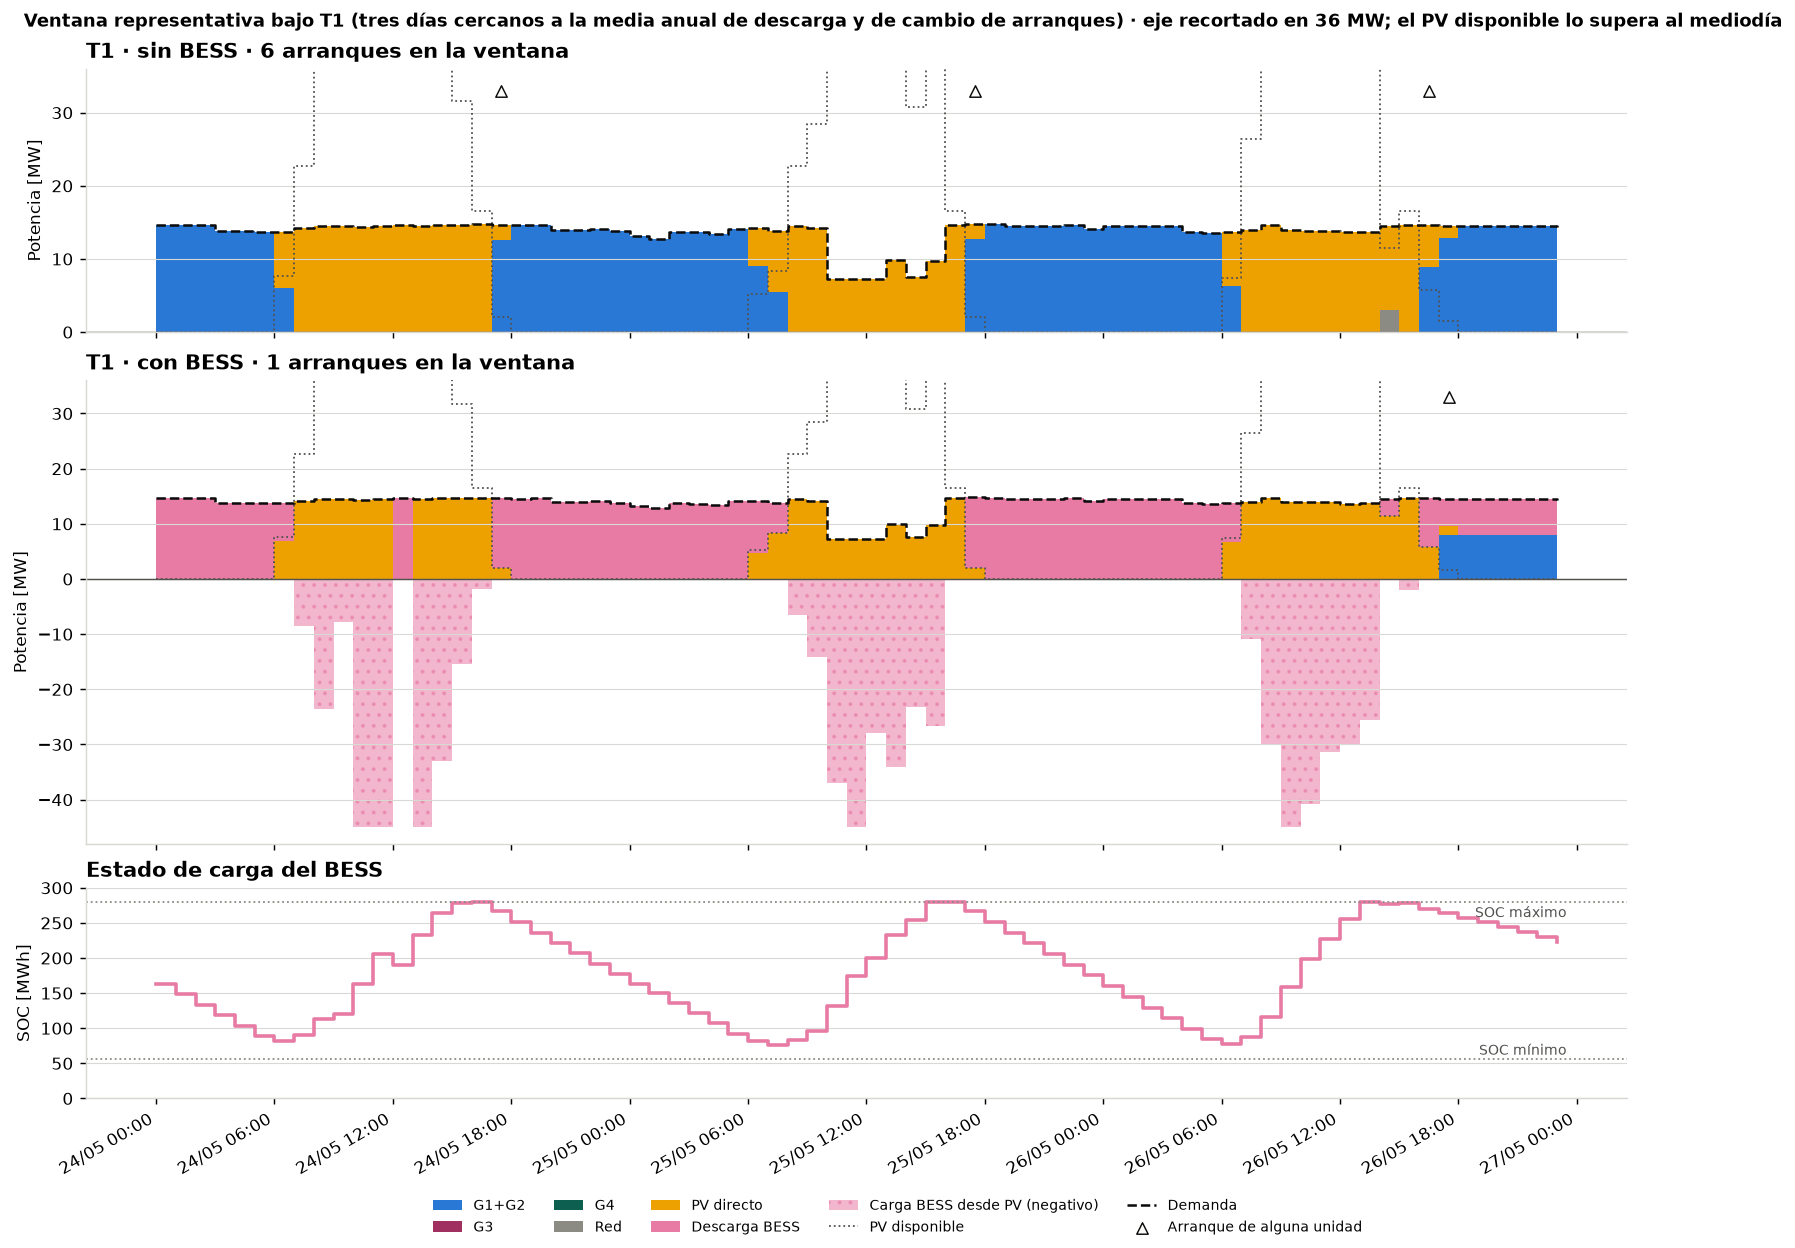

Ventana: 24/05/2025 a 26/05/2025


In [5]:
# B. Ventana representativa bajo T1: tres días cuya descarga del BESS y cambio de arranques
#    están más cerca de la media anual por tres días (no los extremos).
z0 = np.load(NB12/"pv_anual_T1.npz", allow_pickle=False)
z1 = np.load(SAL/"bess_anual_T1.npz", allow_pickle=False)
fechas = pd.DatetimeIndex(z1["Fecha"])
assert (pd.DatetimeIndex(z0["Fecha"]) == fechas).all()
carga = z1["potencia"].sum(axis=1) + z1["pv_directo"] + z1["bess_descarga"]
dias = pd.DataFrame({"desc": z1["bess_descarga"],
                     "darr": z1["arranques"].sum(1) - z0["arranques"].sum(1)}, index=fechas).resample("D").sum()
tres = dias.rolling(3).sum().dropna()
dist = ((tres.desc - tres.desc.mean())/tres.desc.std())**2 + ((tres.darr - tres.darr.mean())/tres.darr.std())**2
fin = tres.index.get_loc(dist.idxmin())
inicio = fechas.get_loc(tres.index[fin] - pd.Timedelta(days=2))
v = slice(inicio, inicio+72); h = np.arange(72)
fig, axs = plt.subplots(3, 1, figsize=(12.5, 9.5), sharex=True, layout="constrained",
                        gridspec_kw={"height_ratios": [1.25, 2.2, 1]})
for ax, z, titulo in [(axs[0], z0, "T1 · sin BESS"), (axs[1], z1, "T1 · con BESS")]:
    p = z["potencia"][v]
    directo = z["pv_directo"][v] if "pv_directo" in z.files else z["pv_usado"][v]
    descarga = z["bess_descarga"][v] if "bess_descarga" in z.files else np.zeros(72)
    ax.stackplot(h, [p[:, 0]+p[:, 1], p[:, 2], p[:, 3], p[:, 4], directo, descarga],
                 colors=[COLOR[k] for k in ("G1+G2", "G3", "G4", "Red", "PV", "BESS")],
                 labels=["G1+G2", "G3", "G4", "Red", "PV directo", "Descarga BESS"], step="post")
    if "bess_carga" in z.files:
        ax.fill_between(h, 0, -z["bess_carga"][v], step="post", color=COLOR["BESS"], alpha=0.55,
                        hatch="..", edgecolor="#52514e", linewidth=0, label="Carga BESS desde PV (negativo)")
    ax.step(h, z["pv_disponible"][v], where="post", color="#52514e", lw=1, ls=":", label="PV disponible")
    ax.step(h, carga[v], where="post", color="#0b0b0b", lw=1.4, ls="--", label="Demanda")
    arr = z["arranques"][v].sum(1)
    ax.scatter(np.flatnonzero(arr)+0.5, np.full(int((arr > 0).sum()), 33), marker="^", s=40,
               color="#fcfcfb", edgecolor="#0b0b0b", linewidth=0.8, zorder=5, label="Arranque de alguna unidad")
    # Misma escala aproximada en MW por altura: el panel sin BESS no tiene flujos negativos.
    ax.set_ylim(-48 if "bess_carga" in z.files else 0, 36)
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.set_ylabel("Potencia [MW]")
    ax.set_title(titulo + " · {} arranques en la ventana".format(int(arr.sum())), loc="left", fontweight="bold")
    ax.grid(axis="x", visible=False)
ax = axs[2]
ax.step(h, z1["soc"][v], where="post", color=COLOR["BESS"], lw=2)
ax.axhline(280*0.2, color="#8b8a83", lw=1, ls=":"); ax.axhline(280, color="#8b8a83", lw=1, ls=":")
ax.text(71.5, 280*0.2+6, "SOC mínimo", ha="right", fontsize=8, color="#52514e")
ax.text(71.5, 280-22, "SOC máximo", ha="right", fontsize=8, color="#52514e")
ax.set_ylim(0, 300); ax.set_ylabel("SOC [MWh]"); ax.set_title("Estado de carga del BESS", loc="left", fontweight="bold")
ax.grid(axis="x", visible=False)
axs[2].set_xticks(np.arange(0, 73, 6), [(fechas[inicio] + pd.Timedelta(hours=int(k))).strftime("%d/%m %H:%M")
                                         for k in range(0, 73, 6)], rotation=30, ha="right")
fig.suptitle("Ventana representativa bajo T1 (tres días cercanos a la media anual de descarga y de cambio de arranques) · "
             "eje recortado en 36 MW; el PV disponible lo supera al mediodía", fontweight="bold", x=0.01, ha="left", fontsize=10)
fig.legend(*axs[1].get_legend_handles_labels(), frameon=False, fontsize=8, ncol=5, loc="outside lower center")
fig.savefig(FIG/"13_2_ventana_representativa_T1.png", dpi=160, bbox_inches="tight")
plt.show()
print("Ventana:", fechas[inicio].strftime("%d/%m/%Y"), "a", fechas[inicio+71].strftime("%d/%m/%Y"))

## 4 · Arranques, horas encendidas y EOH por unidad

Se reconstruyen desde el compromiso:
- **H:** horas encendida.
- **N:** arranques. Estar encendida en la primera hora no cuenta como arranque y
  no se inventa una parada al final.
- **Paradas y energía.**

El bloque G1+G2 es el principal, porque las gemelas admiten óptimos alternativos.

**EOH exploratoria:** `EOH = H + f·N`, con f = 0, 10, 20 y 50 h/arranque
**ilustrativos**, frente al caso PV sin BESS. `f* = −ΔH/ΔN` es el umbral en que
se igualan. Tiene las mismas advertencias que la §7 del cuaderno 12: no es el
contador real de mantenimiento, usa un mismo f para todas las unidades y no se
convierte a dólares.

**Óptimos alternativos frente a cambios operativos.** La tabla de compromiso
separa dos tipos de hora:
- **intercambio G1↔G2:** cambia qué gemela opera, pero no cuántas;
- **cambio del número de gemelas encendidas:** es un cambio operativo.

Los cambios en G3 y G4 se cuentan aparte.

In [6]:
display(UNI.round(0))
display(EOHD.round(2))
display(COMP)
horas = HORA.pivot_table(index=["Senal", "Bloque", "Hora"], columns="Caso", values=["Arranques", "Paradas"]).astype(int)
display(horas.loc[(slice(None), "G1+G2"), :].T)

,Senal,Caso,Unidad,Horas_encendida_h,Arranques,Paradas,Energia_MWh,EOH_f0_h,EOH_f10_h,EOH_f20_h,EOH_f50_h
0,T0,sin_BESS,G1,5385.0,361,361,40666.0,5385.0,8995.0,12605.0,23435.0
1,T0,sin_BESS,G2,5395.0,362,362,40703.0,5395.0,9015.0,12635.0,23495.0
2,T0,sin_BESS,G3,3532.0,293,293,13423.0,3532.0,6462.0,9392.0,18182.0
3,T0,sin_BESS,G4,23.0,2,2,64.0,23.0,43.0,63.0,123.0
4,T0,sin_BESS,G1+G2,10780.0,723,723,81369.0,10780.0,18010.0,25240.0,46930.0
5,T0,sin_BESS,Total,14335.0,1018,1018,94857.0,14335.0,24515.0,34695.0,65235.0
6,T0,con_BESS,G1,2126.0,160,161,13568.0,2126.0,3726.0,5326.0,10126.0
7,T0,con_BESS,G2,2642.0,202,202,17009.0,2642.0,4662.0,6682.0,12742.0
8,T0,con_BESS,G3,0.0,0,0,-0.0,0.0,0.0,0.0,0.0
9,T0,con_BESS,G4,0.0,0,0,-0.0,0.0,0.0,0.0,0.0


,Senal,Comparacion,Unidad,Delta_H_h,Delta_N,Delta_Paradas,Delta_Energia_MWh,Delta_EOH_f0_h,Delta_EOH_f10_h,Delta_EOH_f20_h,Delta_EOH_f50_h,f_equilibrio_h_por_arranque,Tipo_umbral,Lectura,Estado_con_BESS
0,T0,BESS_vs_PV_sin_BESS,G1,-3259.0,-201,-200,-27098.26,-3259.0,-5269.0,-7279.0,-13309.0,-16.21,sin_cruce,f* = -16.21 < 0: ΔH y ΔN tienen el mismo signo...,FACTIBLE_LIMITE_TIEMPO
1,T0,BESS_vs_PV_sin_BESS,G2,-2753.0,-160,-160,-23693.46,-2753.0,-4353.0,-5953.0,-10753.0,-17.21,sin_cruce,f* = -17.21 < 0: ΔH y ΔN tienen el mismo signo...,FACTIBLE_LIMITE_TIEMPO
2,T0,BESS_vs_PV_sin_BESS,G3,-3532.0,-293,-293,-13423.46,-3532.0,-6462.0,-9392.0,-18182.0,-12.05,sin_cruce,f* = -12.05 < 0: ΔH y ΔN tienen el mismo signo...,FACTIBLE_LIMITE_TIEMPO
3,T0,BESS_vs_PV_sin_BESS,G4,-23.0,-2,-2,-64.50,-23.0,-43.0,-63.0,-123.0,-11.50,sin_cruce,f* = -11.5 < 0: ΔH y ΔN tienen el mismo signo;...,FACTIBLE_LIMITE_TIEMPO
4,T0,BESS_vs_PV_sin_BESS,G1+G2,-6012.0,-361,-360,-50791.72,-6012.0,-9622.0,-13232.0,-24062.0,-16.65,sin_cruce,f* = -16.65 < 0: ΔH y ΔN tienen el mismo signo...,FACTIBLE_LIMITE_TIEMPO
5,T0,BESS_vs_PV_sin_BESS,Total,-9567.0,-656,-655,-64279.67,-9567.0,-16127.0,-22687.0,-42367.0,-14.58,sin_cruce,f* = -14.58 < 0: ΔH y ΔN tienen el mismo signo...,FACTIBLE_LIMITE_TIEMPO
6,T1,BESS_vs_PV_sin_BESS,G1,-3479.0,-222,-221,-28150.06,-3479.0,-5699.0,-7919.0,-14579.0,-15.67,sin_cruce,f* = -15.67 < 0: ΔH y ΔN tienen el mismo signo...,FACTIBLE_LIMITE_TIEMPO
7,T1,BESS_vs_PV_sin_BESS,G2,-2838.0,-180,-180,-23569.64,-2838.0,-4638.0,-6438.0,-11838.0,-15.77,sin_cruce,f* = -15.77 < 0: ΔH y ΔN tienen el mismo signo...,FACTIBLE_LIMITE_TIEMPO
8,T1,BESS_vs_PV_sin_BESS,G3,-1997.0,-232,-232,-7348.09,-1997.0,-4317.0,-6637.0,-13597.0,-8.61,sin_cruce,f* = -8.608 < 0: ΔH y ΔN tienen el mismo signo...,FACTIBLE_LIMITE_TIEMPO
9,T1,BESS_vs_PV_sin_BESS,G4,-120.0,-20,-20,-226.85,-120.0,-320.0,-520.0,-1120.0,-6.00,sin_cruce,f* = -6 < 0: ΔH y ΔN tienen el mismo signo; la...,FACTIBLE_LIMITE_TIEMPO


,Senal,Horas_con_algun_cambio,Horas_intercambio_G1_G2,Horas_cambio_numero_G1_G2,Horas_mas_G1_G2_con_BESS,Horas_menos_G1_G2_con_BESS,Horas_cambio_G3,Horas_cambio_G4,Dias_con_cambio_bloque_G1_G2
0,T0,5405,63,4806,6,4800,3532,23,361
1,T1,5221,84,4909,26,4883,1997,120,362


Senal                 T0                                                                                           T1                                                                                      
Bloque             G1+G2                                                                                        G1+G2                                                                                      
Hora                  0  1  2  3   4   5   6    7    8   9   10 11 12 13  14  15   16   17  18  19 20  21 22 23    0  1  2  3   4   5   6    7    8   9   10 11 12 13  14  15   16   17  18  19 20 21 22 23
          Caso                                                                                                                                                                                             
Arranques con_BESS     2  6  4  1   0   1   2    0    0   0   0  0  5  2  10  45   87  117  26  19  9  10  7  9     6  3  0  1   0   2   0    0    0   0   0  0  4  2   9  32   82  110  34  14  9  7  5  1
          sin_BESS     0  1  0  0   0   0   0    0    0   0   0  0  5  5  18  84  183  423   0   0  0   2  0  2     0  1  0  0   0   0   0    0    0   0   0  0  5  6  15  79  185  428   0   0  0  2  0  2
Paradas   con_BESS    10  4  9  8  13  13  38  118  106  21   7  3  1  0   0   0    0    0   1   2  0   3  2  4     7  5  5  4  12  16  24  109   96  22  10  3  1  0   0   0    0    0   1   2  1  1  2  1
          sin_BESS     7  2  0  0   0   0  60  414  183  38  11  3  3  0   2   0    0    0   0   0  0   0  0  0    11  2  0  0   0   0  57  415  181  37  10  3  3  0   0   0    0    0   0   0  1  0  0  3

In [7]:
def lectura_eoh(q):
    mm = lambda x: "menor" if x < 0 else "mayor"
    if q.Tipo_umbral == "cruce":
        return "con f < {} h/arranque la EOH es {}; por encima es {}".format(
            es(q.f_equilibrio_h_por_arranque, 1), mm(q.Delta_H_h), mm(q.Delta_N))
    if q.Tipo_umbral == "sin_cruce":
        return "la EOH es {} para todo f ≥ 0".format(mm(q.Delta_N))
    if q.Tipo_umbral == "umbral_cero":
        return "la EOH coincide en f = 0 y es {} para f > 0".format(mm(q.Delta_N))
    if q.Tipo_umbral == "sin_cambio":
        return "la EOH no cambia"
    return "la EOH es {} para todo f".format(mm(q.Delta_H_h))


texto = []
for s in ("T0", "T1"):
    a, b, d = fila(s, "sin_BESS"), fila(s, "con_BESS"), DIF[DIF.Senal == s].iloc[0]
    nota = "" if b.Estado_solucion == "PRECISION_SOLICITADA" else " *(solución factible limitada por tiempo)*"
    texto.append(
        f"- **{s}{nota}.** Vertimiento {es(a.PV_vertido_MWh/1e3, 1)} → {es(b.PV_vertido_MWh/1e3, 1)} GWh "
        f"({es(a.Vertimiento_pct, 1)} % → {es(b.Vertimiento_pct, 1)} % del PV disponible; −{es(d.Reduccion_vertimiento_pct, 1)} %). "
        f"El BESS toma {es(b.PV_a_BESS_MWh/1e3, 1)} GWh de PV, entrega {es(b.BESS_descarga_demanda_MWh/1e3, 1)} GWh "
        f"y pierde {es(b.BESS_perdidas_MWh/1e3, 2)} GWh; {es(b.BESS_ciclos_equivalentes_util, 0)} ciclos equivalentes "
        f"sobre la capacidad útil. El PV entregado a la demanda pasa de {es(a.PV_entregado_demanda_MWh/1e3, 1)} a "
        f"{es(b.PV_entregado_demanda_MWh/1e3, 1)} GWh ({es(b.Participacion_PV_demanda_pct, 1)} % de la demanda). "
        f"Energía térmica {es(a.Energia_termica_MWh/1e3, 1)} → {es(b.Energia_termica_MWh/1e3, 1)} GWh; compras de red "
        f"{es(a.Compras_red_MWh/1e3, 2)} → {es(b.Compras_red_MWh/1e3, 2)} GWh. Costo operativo "
        f"{es(a.Costo_operativo_total_USD/1e6, 3)} → {es(b.Costo_operativo_total_USD/1e6, 3)} MUSD "
        f"(ahorro {es(d.Ahorro_operativo_USD/1e6, 3)} MUSD, {es(d.Ahorro_operativo_pct, 1)} %), de los cuales los cargos de "
        f"arranque pasan de {es(a.Costo_arranques_USD)} a {es(b.Costo_arranques_USD)} USD. Arranques "
        f"{es(a.Arranques)} → {es(b.Arranques)} (G1+G2 {es(a.Arranques_G1_G2)} → {es(b.Arranques_G1_G2)}, "
        f"G3 {es(a.Arranques_G3)} → {es(b.Arranques_G3)}, G4 {es(a.Arranques_G4)} → {es(b.Arranques_G4)}).")
    partes = []
    for u in ("G1+G2", "G3", "G4", "Total"):
        q = EOHD[(EOHD.Senal == s) & (EOHD.Unidad == u)].iloc[0]
        partes.append(f"{u}: ΔH = {es(q.Delta_H_h)} h, ΔN = {es(q.Delta_N)}; {lectura_eoh(q)}")
    texto.append(f"- **{s}, EOH frente a PV sin BESS.** " + ". ".join(partes) + ".")
    c = COMP[COMP.Senal == s].iloc[0]
    texto.append(
        f"- **{s}, compromiso.** {es(c.Horas_con_algun_cambio)} horas con algún cambio. De ellas, "
        f"{es(c.Horas_intercambio_G1_G2)} son solo intercambio G1↔G2 (óptimo alternativo posible) y en "
        f"{es(c.Horas_cambio_numero_G1_G2)} cambia cuántas gemelas operan ({es(c.Horas_mas_G1_G2_con_BESS)} con más, "
        f"{es(c.Horas_menos_G1_G2_con_BESS)} con menos; {es(c.Dias_con_cambio_bloque_G1_G2)} días). G3 cambia en "
        f"{es(c.Horas_cambio_G3)} horas y G4 en {es(c.Horas_cambio_G4)}.")
display(Markdown("\n".join(texto)))

- **T0 *(solución factible limitada por tiempo)*.** Vertimiento 96,0 → 23,2 GWh (60,5 % → 14,6 % del PV disponible; −75,9 %). El BESS toma 74,4 GWh de PV, entrega 66,9 GWh y pierde 7,44 GWh; 299 ciclos equivalentes sobre la capacidad útil. El PV entregado a la demanda pasa de 62,7 a 128,1 GWh (80,7 % de la demanda). Energía térmica 94,9 → 30,6 GWh; compras de red 1,16 → 0,02 GWh. Costo operativo 16,168 → 5,040 MUSD (ahorro 11,128 MUSD, 68,8 %), de los cuales los cargos de arranque pasan de 101.800 a 36.200 USD. Arranques 1.018 → 362 (G1+G2 723 → 362, G3 293 → 0, G4 2 → 0).
- **T0, EOH frente a PV sin BESS.** G1+G2: ΔH = -6.012 h, ΔN = -361; la EOH es menor para todo f ≥ 0. G3: ΔH = -3.532 h, ΔN = -293; la EOH es menor para todo f ≥ 0. G4: ΔH = -23 h, ΔN = -2; la EOH es menor para todo f ≥ 0. Total: ΔH = -9.567 h, ΔN = -656; la EOH es menor para todo f ≥ 0.
- **T0, compromiso.** 5.405 horas con algún cambio. De ellas, 63 son solo intercambio G1↔G2 (óptimo alternativo posible) y en 4.806 cambia cuántas gemelas operan (6 con más, 4.800 con menos; 361 días). G3 cambia en 3.532 horas y G4 en 23.
- **T1 *(solución factible limitada por tiempo)*.** Vertimiento 96,0 → 23,2 GWh (60,5 % → 14,6 % del PV disponible; −75,9 %). El BESS toma 74,3 GWh de PV, entrega 66,9 GWh y pierde 7,43 GWh; 299 ciclos equivalentes sobre la capacidad útil. El PV entregado a la demanda pasa de 62,7 a 128,1 GWh (80,7 % de la demanda). Energía térmica 88,3 → 29,0 GWh; compras de red 7,70 → 1,57 GWh. Costo operativo 16,048 → 5,039 MUSD (ahorro 11,009 MUSD, 68,6 %), de los cuales los cargos de arranque pasan de 97.500 a 32.100 USD. Arranques 975 → 321 (G1+G2 723 → 321, G3 232 → 0, G4 20 → 0).
- **T1, EOH frente a PV sin BESS.** G1+G2: ΔH = -6.317 h, ΔN = -402; la EOH es menor para todo f ≥ 0. G3: ΔH = -1.997 h, ΔN = -232; la EOH es menor para todo f ≥ 0. G4: ΔH = -120 h, ΔN = -20; la EOH es menor para todo f ≥ 0. Total: ΔH = -8.434 h, ΔN = -654; la EOH es menor para todo f ≥ 0.
- **T1, compromiso.** 5.221 horas con algún cambio. De ellas, 84 son solo intercambio G1↔G2 (óptimo alternativo posible) y en 4.909 cambia cuántas gemelas operan (26 con más, 4.883 con menos; 362 días). G3 cambia en 1.997 horas y G4 en 120.

## 5 · Referencia económica del BESS

El CAPEX y el OPEX del BESS se reportan aparte del costo operativo, con la
convención de curvas vigente. La diferencia entre el ahorro operativo del año y
el OPEX del BESS **no es un VPN ni una rentabilidad**: faltan el CAPEX, la
degradación, la reposición, el horizonte y el descuento.

In [8]:
display(ECO.T)
for _, e in ECO.iterrows():
    print("{}: CAPEX BESS {} MUSD; OPEX BESS {} MUSD/año; ahorro operativo del BESS {} MUSD/año; ahorro − OPEX {} MUSD/año".format(
        e.Senal, es(e.CAPEX_BESS_USD/1e6, 2), es(e.OPEX_BESS_anual_USD/1e6, 3),
        es(e.Ahorro_operativo_BESS_USD/1e6, 3), es(e.Ahorro_operativo_menos_OPEX_BESS_USD/1e6, 3)))

,0,1
Senal,T0,T1
P_BESS_MW,45.0,45.0
E_BESS_MWh,280.0,280.0
Duracion_h,6.222222,6.222222
CAPEX_BESS_USD,50418808.0375,50418808.0375
OPEX_BESS_anual_USD,756282.120562,756282.120562
OPEX_fraccion_CAPEX,0.015,0.015
TRM_COP_USD,3126.08,3126.08
Fuente,costos.capex_bess (CurvasCapexPVBESS.xlsx) y c...,costos.capex_bess (CurvasCapexPVBESS.xlsx) y c...
CAPEX_PV_USD,76978811.286364,76978811.286364


T0: CAPEX BESS 50,42 MUSD; OPEX BESS 0,756 MUSD/año; ahorro operativo del BESS 11,128 MUSD/año; ahorro − OPEX 10,372 MUSD/año
T1: CAPEX BESS 50,42 MUSD; OPEX BESS 0,756 MUSD/año; ahorro operativo del BESS 11,009 MUSD/año; ahorro − OPEX 10,253 MUSD/año


## 6 · Limitaciones

- **Un solo tamaño.** K3 viene del estudio PV+BESS con exportación. No se
  optimiza aquí ni se optimizan juntos PV y BESS.
- **Previsión perfecta del año.** Es una cota de lo que el almacenamiento puede
  hacer, no una política implementable.
- **Carga solo desde PV y sin exportación.** Son decisiones de esta primera
  comparación, no conclusiones.
- **Sin costo de degradación ni de mantenimiento del BESS** en el despacho. Los
  ciclos equivalentes se informan, pero no se penalizan.
- **SOC inicial y final fijados en 60 %.** Es un nivel explícito, no optimizado.
- **Supuestos del caso 1:** cargo de arranque hipotético, sin rampas, sin consumo
  de arranque ni curva a carga parcial y TRM congelada.
- **EOH exploratoria**, con factores ilustrativos.

## 7 · Costo frente al límite anual de arranques con BESS

Se mantienen PV = 114,415 MWp y BESS = 45 MW / 280 MWh. T0 y T1 son las
señales canónicas del notebook 02: **no se recalibran entre escenarios**.
El cargo hipotético sigue en 100 USD/arranque y el gas en 16 USD/MMBtu.

Los límites 180, 60 y 0 son **por unidad y por año**, además de un arranque
y una parada diarios. El punto 365 no agrega una restricción efectiva al
límite diario del año 2025. La frontera térmica es libre: con límite cero una
unidad puede comenzar encendida y seguir operando. No es una prohibición de
generar ni una recomendación de funcionamiento continuo.

Los seis casos nuevos se resuelven con presupuesto explícito de 600 s cada uno.
Se repara la simultaneidad sin cambiar el compromiso ni el costo y se valida
la trayectoria guardada. **La reparación no elimina la brecha del solver.**
Los candidatos se conservan; una trayectoria de un escenario más estricto
puede mejorar otro más holgado si cumple sus restricciones. Las referencias
originales de los casos 1 y 2 permanecen intactas.

,Senal,Limite_anual_por_unidad,Costo_operativo_total_USD,Cota_dual_USD,Brecha,Sobrecosto_min_USD,Sobrecosto_max_USD,Arranques,Arranques_G1_G2,Arranques_G3,Arranques_G4,Energia_termica_MWh,Compras_red_MWh,Vertimiento_pct
0,T0,365,5.039929e+06,5.031990e+06,1.575064e-03,0.000000e+00,0.000000e+00,362,362,0,0,30577.109325,22.675238,14.592004
1,T0,180,5.044114e+06,5.032405e+06,2.321458e-03,0.000000e+00,1.212378e+04,360,360,0,0,30476.400085,122.456797,14.587625
2,T0,60,5.267572e+06,5.107989e+06,3.029535e-02,6.806016e+04,2.355813e+05,158,120,35,3,28724.819101,2511.053993,14.800504
3,T0,0,6.372313e+06,6.372313e+06,1.885353e-14,1.332384e+06,1.340322e+06,0,0,0,0,545.065422,30066.816943,14.700608
4,T1,365,5.038379e+06,5.031754e+06,1.314856e-03,0.000000e+00,0.000000e+00,317,317,0,0,28826.269776,1773.888418,14.591340
5,T1,180,5.038379e+06,5.032111e+06,1.243931e-03,0.000000e+00,6.624743e+03,317,317,0,0,28826.269776,1773.888418,14.591340
6,T1,60,5.126165e+06,5.068696e+06,1.121096e-02,3.031697e+04,9.441093e+04,129,120,9,0,17087.954085,13649.190482,14.611119
7,T1,0,5.627172e+06,5.627172e+06,2.085357e-14,5.887934e+05,5.954181e+05,0,0,0,0,2993.779808,28442.436888,15.201405


El punto 365 de T1 reutiliza la trayectoria del límite 180 por tener menor costo factible. La referencia original se conserva. Esto mejora la solución encontrada, no significa que restringir el modelo abarate su óptimo.


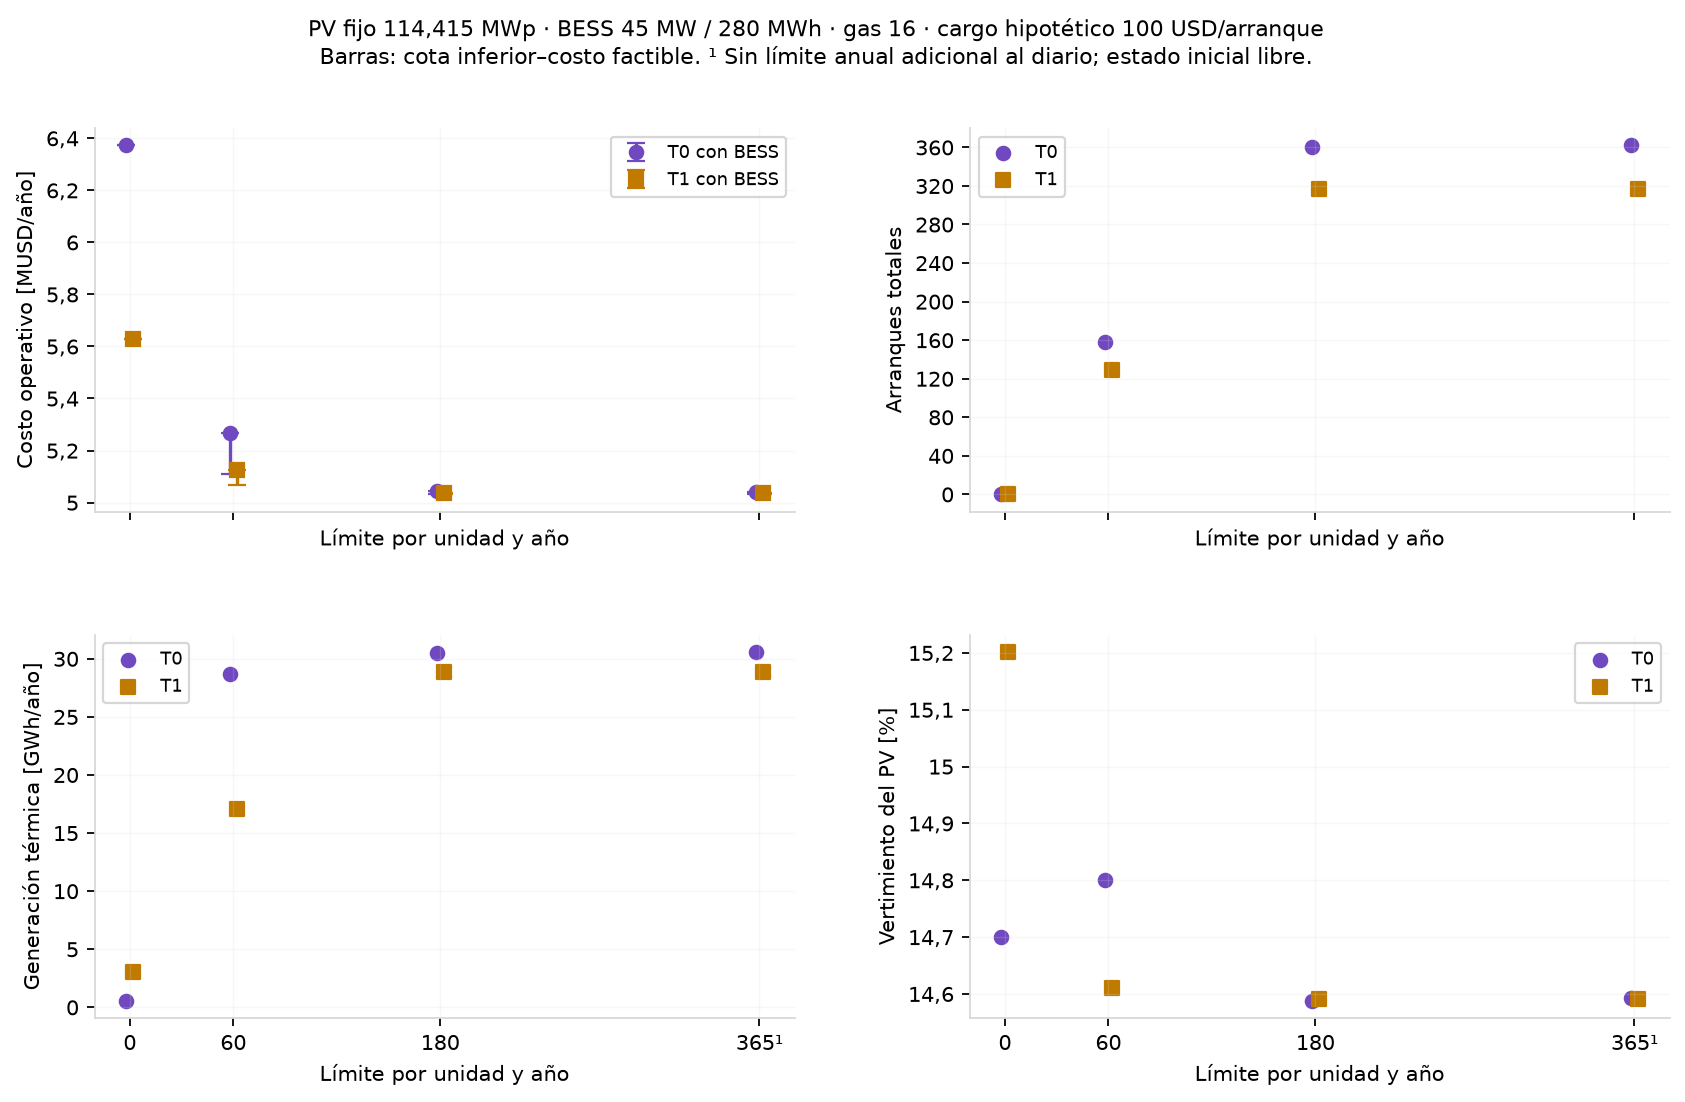

In [9]:
from termica_bess_limites import graficar as _graficar_limites
LB = pd.read_csv(SAL / "limites_bess_resumen.csv", float_precision="round_trip")
LV = pd.read_csv(SAL / "limites_bess_validaciones.csv")
LP = pd.read_csv(SAL / "limites_bess_pruebas.csv")
LU = pd.read_csv(SAL / "limites_bess_unidades_eoh.csv")
assert len(LB) == 8 and len(LV) == 8 and len(LP) == 13
assert len(LU) == 48
_unidades = LU[LU.Unidad.isin(["G1", "G2", "G3", "G4"])]
assert len(_unidades) == 32
assert (_unidades.Arranques <= _unidades.Limite_anual_por_unidad).all()
assert LU.groupby(["Senal", "Limite_anual_por_unidad", "Unidad"]).size().eq(1).all()
assert (LV.Estado == "OK").all() and (LP.Estado == "OK").all()
assert LB.groupby("Senal").Huella_senal.nunique().eq(1).all()
assert LB.Huella_entradas.nunique() == 1
assert LB.groupby(["Senal", "Limite_anual_por_unidad"]).size().eq(1).all()
assert (LB.Cota_dual_USD <= LB.Costo_operativo_total_USD + 1e-4).all()
assert (LB.Arranques <= 4*LB.Limite_anual_por_unidad).all()
assert (LB.Cota_dual_USD <= LB.Costo_sin_BESS_USD + 1e-4).all()
tabla_limites = LB[["Senal", "Limite_anual_por_unidad", "Costo_operativo_total_USD",
                   "Cota_dual_USD", "Brecha", "Sobrecosto_min_USD", "Sobrecosto_max_USD",
                   "Arranques", "Arranques_G1_G2", "Arranques_G3", "Arranques_G4",
                   "Energia_termica_MWh", "Compras_red_MWh", "Vertimiento_pct"]]
display(tabla_limites)
for _, _r in LB[(LB.Limite_anual_por_unidad == 365) & (LB.Limite_origen_trayectoria != 365)].iterrows():
    print("El punto 365 de {} reutiliza la trayectoria del límite {} por tener menor costo factible. La referencia original se conserva. Esto mejora la solución encontrada, no significa que restringir el modelo abarate su óptimo.".format(_r.Senal, int(_r.Limite_origen_trayectoria)))
_graficar_limites(LB)  # Esta función solo grafica; no carga entradas ni importa el solver.
display(__import__("IPython.display", fromlist=["Image"]).Image(filename=str(FIG / "13_3_limites_arranques_bess.png")))

### Lectura de cotas y comparación con el caso sin BESS

El óptimo está entre la cota inferior y el costo factible. Para dos límites,
el sobrecosto se acota con `máx(0, cota_estricta − costo_holgado)` y
`costo_estricto − cota_holgada`. Son cotas deterministas, **no intervalos de
confianza**. Si el intervalo incluye cero, el sobrecosto no queda resuelto a
esta precisión. No se exige monotonía de los conteos de soluciones alternativas.

La comparación contra el caso sin BESS usa su mismo límite anual y las mismas
entradas. El BESS en reposo es una solución admisible, así que el óptimo con
BESS no puede ser más caro. Las soluciones factibles obtenidas por tiempo no
necesariamente expresan esa propiedad: se comparan también las cotas.

In [10]:
for _, r in LB.sort_values(["Senal", "Limite_anual_por_unidad"], ascending=[True, False]).iterrows():
    descripcion = "sin límite adicional" if r.Limite_anual_por_unidad == 365 else "límite {}".format(int(r.Limite_anual_por_unidad))
    print("{} · {}: óptimo entre {} y {} MUSD; brecha {} %; {} arranques en la trayectoria elegida.".format(
        r.Senal, descripcion, es(r.Cota_dual_USD/1e6, 4), es(r.Costo_operativo_total_USD/1e6, 4),
        es(100*r.Brecha, 3), es(r.Arranques)))
    if r.Limite_anual_por_unidad != 365:
        print("  Sobrecosto frente a referencia BESS: entre {} y {} USD/año. {}".format(
            es(r.Sobrecosto_min_USD, 0), es(r.Sobrecosto_max_USD, 0),
            "Incluye cero: diferencia no resuelta a esta precisión." if r.Sobrecosto_min_USD <= 1e-4 else "Sobrecosto positivo certificado por las cotas."))
    print("  Ahorro operativo del BESS frente al mismo límite sin BESS: entre {} y {} MUSD/año.".format(
        es(r.Ahorro_BESS_min_USD/1e6, 3), es(r.Ahorro_BESS_max_USD/1e6, 3)))

display(LU[LU.Unidad.isin(["G1+G2", "G3", "G4", "Total"])])

T0 · sin límite adicional: óptimo entre 5,0320 y 5,0399 MUSD; brecha 0,158 %; 362 arranques en la trayectoria elegida.
  Ahorro operativo del BESS frente al mismo límite sin BESS: entre 11,128 y 11,136 MUSD/año.
T0 · límite 180: óptimo entre 5,0324 y 5,0441 MUSD; brecha 0,232 %; 360 arranques en la trayectoria elegida.
  Sobrecosto frente a referencia BESS: entre 0 y 12.124 USD/año. Incluye cero: diferencia no resuelta a esta precisión.
  Ahorro operativo del BESS frente al mismo límite sin BESS: entre 12,174 y 12,185 MUSD/año.
T0 · límite 60: óptimo entre 5,1080 y 5,2676 MUSD; brecha 3,030 %; 158 arranques en la trayectoria elegida.
  Sobrecosto frente a referencia BESS: entre 68.060 y 235.581 USD/año. Sobrecosto positivo certificado por las cotas.
  Ahorro operativo del BESS frente al mismo límite sin BESS: entre 12,949 y 13,138 MUSD/año.
T0 · límite 0: óptimo entre 6,3723 y 6,3723 MUSD; brecha 0,000 %; 0 arranques en la trayectoria elegida.
  Sobrecosto frente a referencia BESS: ent

,Senal,Limite_anual_por_unidad,Unidad,Horas_encendida_h,Arranques,Paradas,Energia_MWh,EOH_f0_h,EOH_f10_h,EOH_f20_h,EOH_f50_h
2,T0,365,G3,0.0,0,0,-6.405987e-14,0.0,0.0,0.0,0.0
3,T0,365,G4,0.0,0,0,-1.170262e-13,0.0,0.0,0.0,0.0
4,T0,365,G1+G2,4768.0,362,363,3.057711e+04,4768.0,8388.0,12008.0,22868.0
5,T0,365,Total,4768.0,362,363,3.057711e+04,4768.0,8388.0,12008.0,22868.0
8,T0,180,G3,0.0,0,0,7.578033e-14,0.0,0.0,0.0,0.0
9,T0,180,G4,0.0,0,0,-4.717062e-13,0.0,0.0,0.0,0.0
10,T0,180,G1+G2,4680.0,360,362,3.047640e+04,4680.0,8280.0,11880.0,22680.0
11,T0,180,Total,4680.0,360,362,3.047640e+04,4680.0,8280.0,11880.0,22680.0
14,T0,60,G3,295.0,35,34,1.223228e+03,295.0,645.0,995.0,2045.0
15,T0,60,G4,27.0,3,3,6.007408e+01,27.0,57.0,87.0,177.0


Al endurecer el límite, se deben revisar también las compras de red y el PV
entregado a la demanda: menos generación térmica no demuestra por sí sola
más aprovechamiento solar.

Los factores de EOH siguen siendo ilustrativos. Los arranques y horas son los
de las trayectorias factibles obtenidas: no se certifica un reparto único entre
G1 y G2 ni un contador real de mantenimiento. Este experimento a tamaño fijo
no dimensiona ni elige automáticamente un límite operativo recomendado.

Fuentes: `termica_bess_limites.py`, `termica_bess_limites_pruebas.py` y
`resultados_nb13/limites_bess_*`. La figura se regenera con `--solo-figura`
sin optimizar; `--solo-resumen` revalida candidatos y reconstruye tablas.

## 8 · Costo de arranque sin imponer un límite anual

El límite de 60 de §7 queda como sensibilidad; no se adopta como restricción
de diseño. Aquí el optimizador decide los arranques frente a un cargo común
de **0, 100, 500 o 2.000 USD/arranque**, sin tope anual y conservando el límite
diario comunicado por el cliente. PV, BESS, gas, mínimos y tarifas permanecen fijos.

### Estimación por componentes

\[
C_g=Q_{g,extra}\,p_{gas}+A_{g,extra}+f_g k_g,
\qquad k_g\approx M_g/H_{g,intervalo}.
\]

Los consumos deben ser adicionales a los ya cobrados por el despacho. Q,
auxiliares y provisión de mantenimiento de las unidades permanecen desconocidos.
La figura muestra **mallas exploratorias**, no rangos certificados ni valores
asignados a G1–G4. El CVOM existente no se desagrega: no se afirma haber calibrado
el costo incremental de mantenimiento ni se añade una provisión horaria encima.

La [referencia NREL/Intertek](https://docs.nlr.gov/docs/fy12osti/55433.pdf) aporta
componentes genéricos, en USD de 2011 y para otras clases de turbinas. Se conserva
separada de los precios actuales. Detalle y trazabilidad en `COSTO_ARRANQUE.md`.

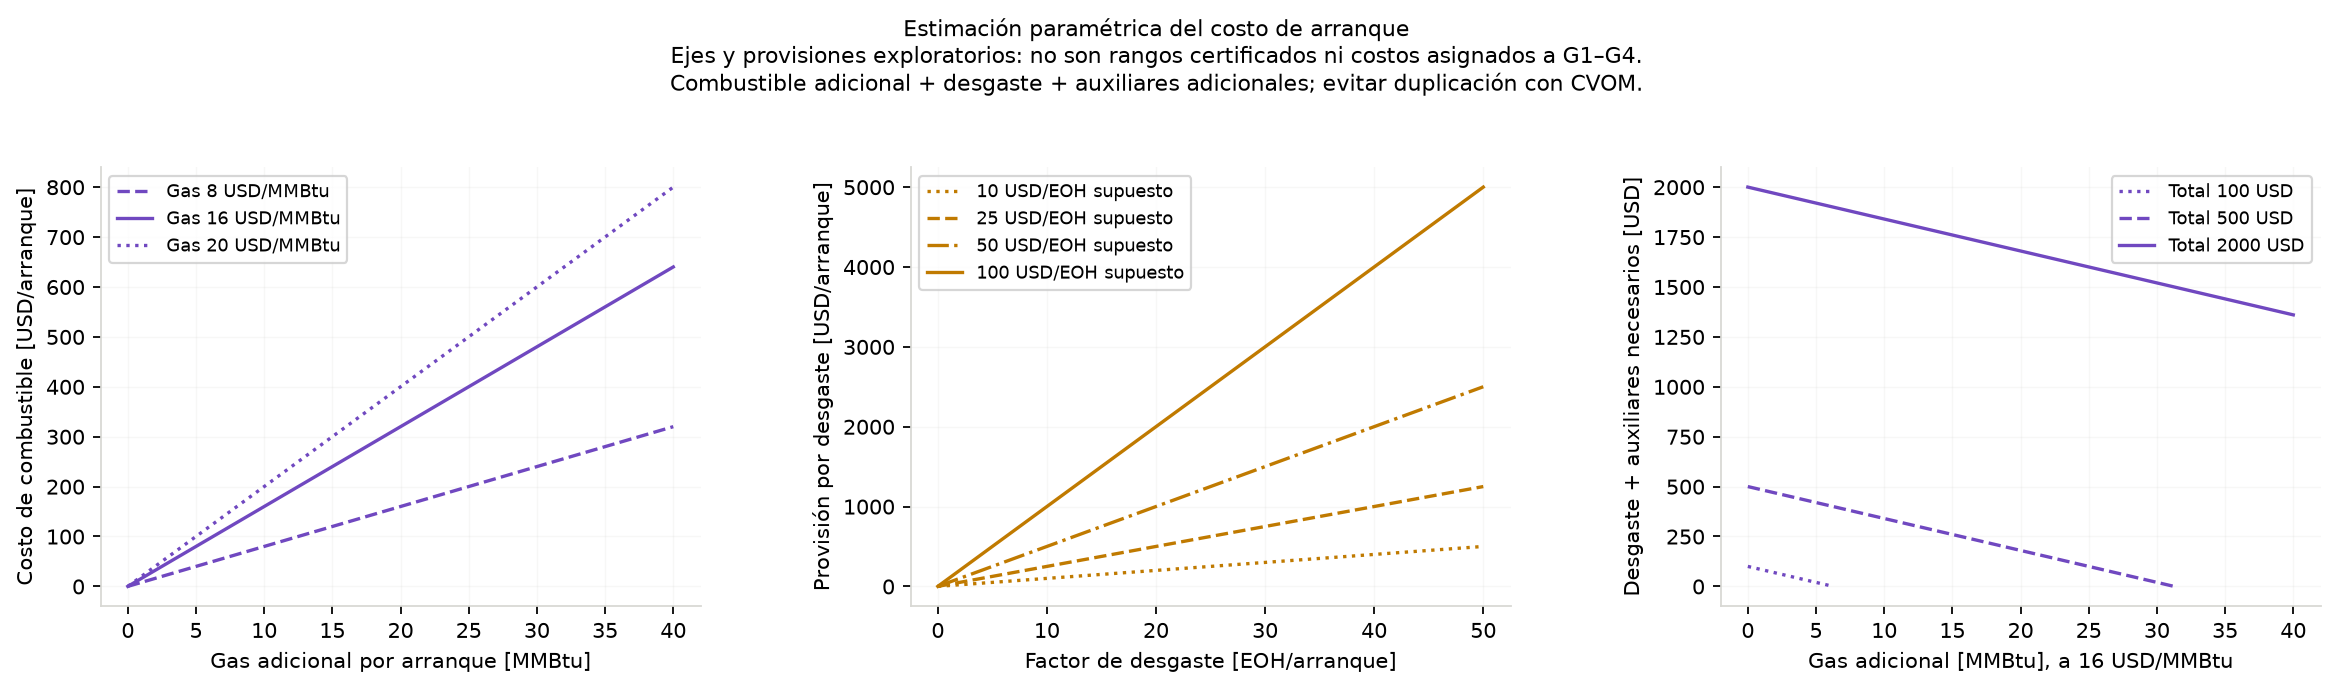

In [11]:
from termica_costo_arranque import graficar_componentes as _fig_componentes
from termica_bess_cargos import graficar as _fig_cargos
CQ = pd.read_csv(SAL / "costo_arranque_combustible.csv")
CF = pd.read_csv(SAL / "costo_arranque_desgaste.csv")
CP = pd.read_csv(SAL / "costo_arranque_parametros_pendientes.csv")
assert len(CP) == 4 and CP.Q_extra_MMBtu.eq("PENDIENTE").all()
_fig_componentes(CQ, CF)
display(__import__("IPython.display", fromlist=["Image"]).Image(filename=str(FIG / "13_4_componentes_costo_arranque.png")))

El tercer panel muestra combinaciones de gas y desgaste más auxiliares que producirían cada cargo. No selecciona una combinación ni identifica el costo real.

### Respuesta del despacho y cotas

La malla de cargos no es una estimación probabilística bajo/central/alto. Su
objetivo es observar la respuesta económica sin forzar un número de arranques.
Se separa **costo energético** de **cargo supuesto**: cambiar el coeficiente
cambia la valoración del objetivo, no solo la operación física.

Cada punto nuevo recibe 600 s de solver. Las líneas eligen la mejor trayectoria
archivada a cada cargo; los puntos intermedios no se optimizaron de nuevo.
Las bandas acotan el costo óptimo, no los conteos de arranques. Las trayectorias
del estudio con límite pueden reutilizarse por factibilidad, pero sus cotas
duales restringidas no acotan este problema sin límite anual.

,Senal,Cargo_USD_arranque,Arranques,Costo_energia_USD,Costo_operativo_total_USD,Cota_dual_USD,Brecha,Energia_termica_MWh,Compras_red_MWh,Vertimiento_pct
0,T0,0.0,646,5.002443e+06,5.002443e+06,5.002443e+06,2.531960e-14,30598.226587,1.152183e-13,14.598928
1,T0,100.0,362,5.003729e+06,5.039929e+06,5.031990e+06,1.575064e-03,30577.109325,2.267524e+01,14.592004
2,T0,500.0,277,5.038798e+06,5.177298e+06,5.128956e+06,9.337322e-03,30403.142482,3.266155e+02,14.591592
3,T0,2000.0,153,5.164165e+06,5.470165e+06,5.366464e+06,1.895761e-02,29814.536037,1.387092e+03,14.785147
4,T1,0.0,641,5.002408e+06,5.002408e+06,5.002408e+06,4.356492e-14,30375.463849,2.227627e+02,14.596423
5,T1,100.0,317,5.006679e+06,5.038379e+06,5.031754e+06,1.314856e-03,28826.269776,1.773888e+03,14.591340
6,T1,500.0,163,5.045514e+06,5.127014e+06,5.115866e+06,2.174539e-03,19550.172589,1.111961e+04,14.589341
7,T1,2000.0,67,5.142670e+06,5.276670e+06,5.250724e+06,4.917000e-03,12379.263225,1.843085e+04,14.653738


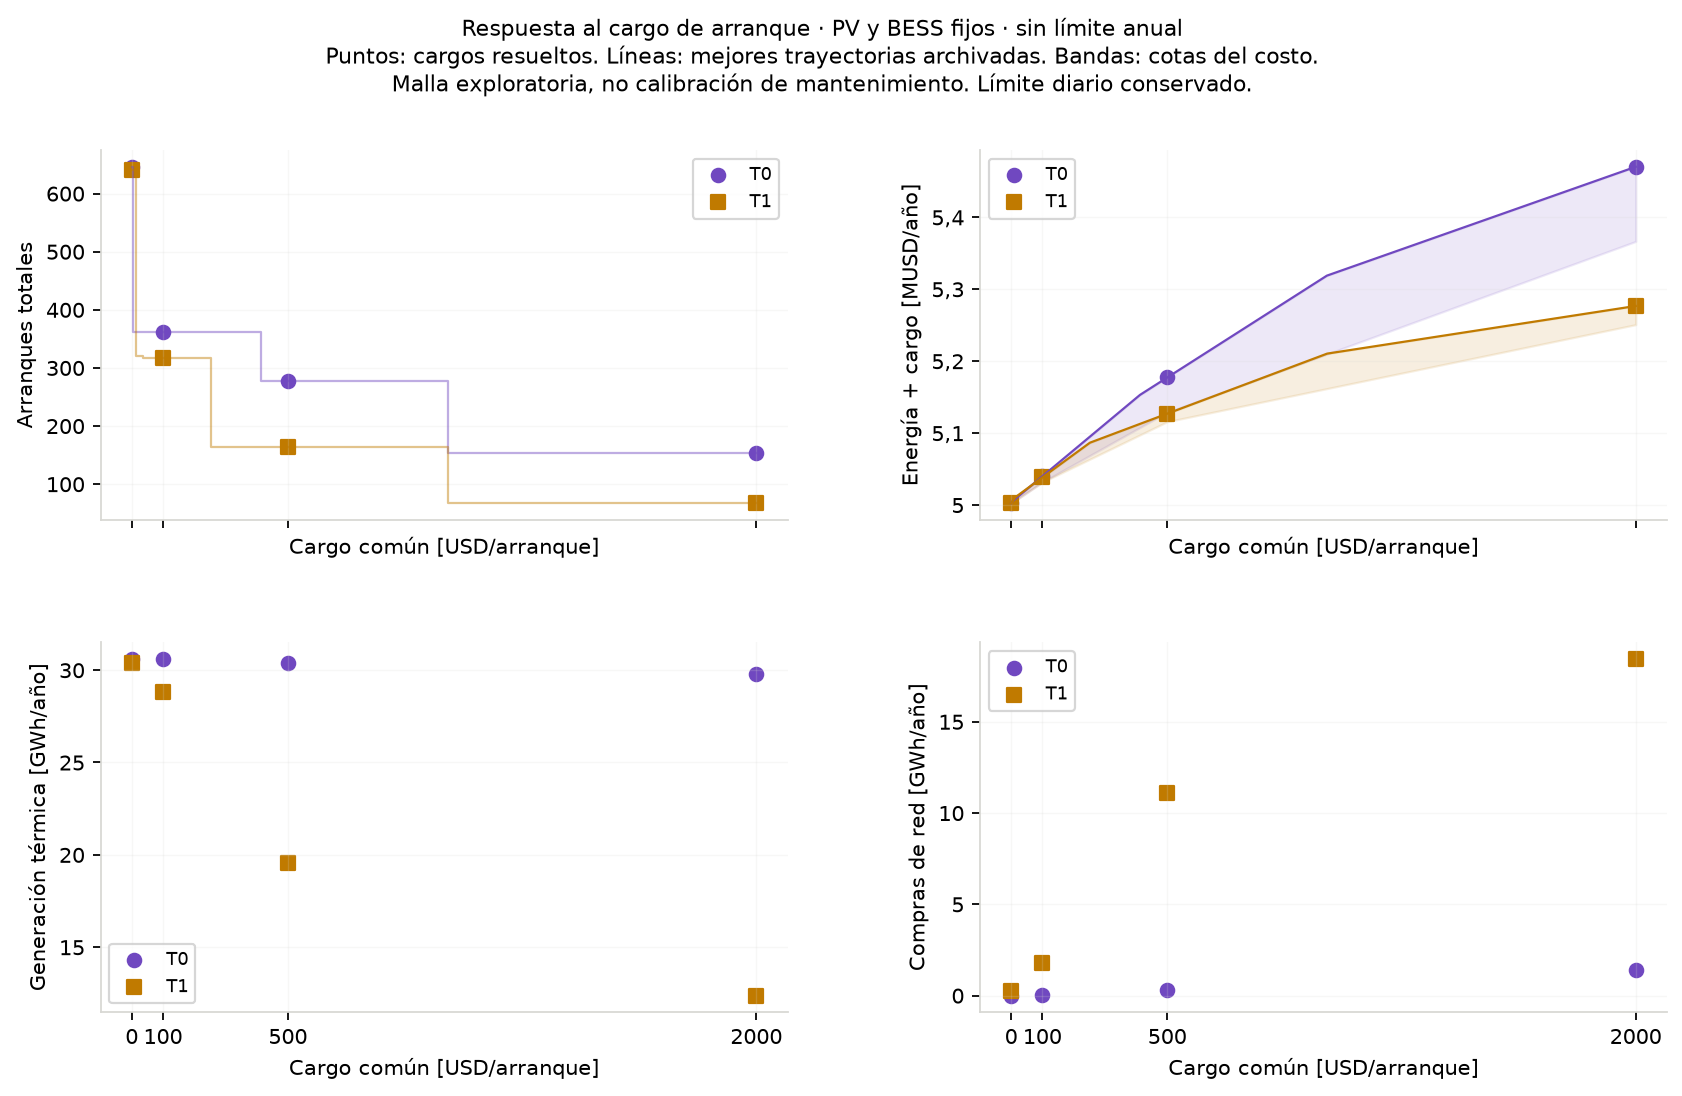

T0 · 0 USD/arranque: 646 arranques; energía 5,0024 MUSD; objetivo entre 5,0024 y 5,0024 MUSD; brecha 0,000 %.
T0 · 100 USD/arranque: 362 arranques; energía 5,0037 MUSD; objetivo entre 5,0320 y 5,0399 MUSD; brecha 0,158 %.
T0 · 500 USD/arranque: 277 arranques; energía 5,0388 MUSD; objetivo entre 5,1290 y 5,1773 MUSD; brecha 0,934 %.
T0 · 2.000 USD/arranque: 153 arranques; energía 5,1642 MUSD; objetivo entre 5,3665 y 5,4702 MUSD; brecha 1,896 %.
T1 · 0 USD/arranque: 641 arranques; energía 5,0024 MUSD; objetivo entre 5,0024 y 5,0024 MUSD; brecha 0,000 %.
T1 · 100 USD/arranque: 317 arranques; energía 5,0067 MUSD; objetivo entre 5,0318 y 5,0384 MUSD; brecha 0,131 %.
T1 · 500 USD/arranque: 163 arranques; energía 5,0455 MUSD; objetivo entre 5,1159 y 5,1270 MUSD; brecha 0,217 %.
T1 · 2.000 USD/arranque: 67 arranques; energía 5,1427 MUSD; objetivo entre 5,2507 y 5,2767 MUSD; brecha 0,492 %.


,Senal,Cargo_USD_arranque,Unidad,Horas_encendida_h,Arranques,Paradas,Energia_MWh,EOH_f0_h,EOH_f10_h,EOH_f20_h,EOH_f50_h
2,T0,0.0,G3,0.0,0,0,4.281968e-15,0.0,0.0,0.0,0.0
3,T0,0.0,G4,0.0,0,0,-2.011169e-13,0.0,0.0,0.0,0.0
4,T0,0.0,G1+G2,5489.0,646,646,3.059823e+04,5489.0,11949.0,18409.0,37789.0
5,T0,0.0,Total,5489.0,646,646,3.059823e+04,5489.0,11949.0,18409.0,37789.0
8,T0,100.0,G3,0.0,0,0,-6.405987e-14,0.0,0.0,0.0,0.0
9,T0,100.0,G4,0.0,0,0,-1.170262e-13,0.0,0.0,0.0,0.0
10,T0,100.0,G1+G2,4768.0,362,363,3.057711e+04,4768.0,8388.0,12008.0,22868.0
11,T0,100.0,Total,4768.0,362,363,3.057711e+04,4768.0,8388.0,12008.0,22868.0
14,T0,500.0,G3,0.0,0,0,2.118615e-13,0.0,0.0,0.0,0.0
15,T0,500.0,G4,0.0,0,0,3.057478e-12,0.0,0.0,0.0,0.0


In [12]:
CR = pd.read_csv(SAL / "cargos_bess_resumen.csv", float_precision="round_trip")
CE = pd.read_csv(SAL / "cargos_bess_envolvente.csv", float_precision="round_trip")
CV = pd.read_csv(SAL / "cargos_bess_validaciones.csv")
CT = pd.read_csv(SAL / "cargos_bess_pruebas.csv")
CU = pd.read_csv(SAL / "cargos_bess_unidades.csv")
assert len(CR) == len(CV) == 8 and len(CT) == 11 and len(CU) == 48
assert (CV.Estado == "OK").all() and (CT.Estado == "OK").all()
assert CR.Sin_limite_anual.all() and CR.Huella_contexto.nunique() == 1
assert set(zip(CR.Senal, CR.Cargo_USD_arranque)) == {(s,c) for s in ("T0","T1") for c in (0,100,500,2000)}
assert (CR.Cota_dual_USD <= CR.Costo_operativo_total_USD + 1e-4).all()
assert (CE.Cota_inferior_USD <= CE.Costo_factible_USD + 1e-4).all()
assert np.allclose(CR.Costo_operativo_total_USD, CR.Costo_energia_USD + CR.Cargo_USD_arranque*CR.Arranques, rtol=0, atol=1e-4)
for s in ("T0","T1"):
    _t = CR[CR.Senal == s].sort_values("Cargo_USD_arranque")
    assert (np.diff(_t.Arranques) <= 0).all()
display(CR[["Senal","Cargo_USD_arranque","Arranques","Costo_energia_USD","Costo_operativo_total_USD",
            "Cota_dual_USD","Brecha","Energia_termica_MWh","Compras_red_MWh","Vertimiento_pct"]])
_fig_cargos(CR, CE)
display(__import__("IPython.display", fromlist=["Image"]).Image(filename=str(FIG / "13_5_respuesta_cargo_arranque.png")))
for _, r in CR.sort_values(["Senal","Cargo_USD_arranque"]).iterrows():
    print("{} · {} USD/arranque: {} arranques; energía {} MUSD; objetivo entre {} y {} MUSD; brecha {} %.".format(
        r.Senal, es(r.Cargo_USD_arranque), es(r.Arranques), es(r.Costo_energia_USD/1e6,4),
        es(r.Cota_dual_USD/1e6,4), es(r.Costo_operativo_total_USD/1e6,4), es(100*r.Brecha,3)))
display(CU[CU.Unidad.isin(["G1+G2","G3","G4","Total"])])

Este estudio no estima un cargo a partir de un objetivo de 60 arranques. Las
unidades pueden permanecer encendidas más tiempo para ahorrar eventos; por eso
se conservan horas, energía y arranques. La caída de generación térmica tampoco
demuestra por sí sola más aprovechamiento solar: hay que revisar compras de red.

La frontera inicial sigue libre: una unidad inicialmente encendida no paga un
arranque inicial. No se agrega una parada al final. El cargo común es una
simplificación para comparar con la referencia; no afirma que el desgaste de
equipos distintos tenga el mismo costo real. Los resultados anteriores se conservan.

Una reducción de arranques o de generación térmica puede trasladar suministro a
la red. No demuestra por sí sola mayor desplazamiento por PV y BESS: deben
examinarse juntas las compras de red, el aprovechamiento solar y el almacenamiento.